In [ ]:
import sys; sys.path.append("..")
import pandas as pd
from sqlalchemy import text
from src.complaint.db import get_engine
engine = get_engine()

from pathlib import Path
import pandas as pd

DATA = Path("/mnt/c/Users/leomu/Downloads/complaint-triage")
train, val, test = (pd.read_parquet(DATA / f"{s}.parquet") for s in ["train", "val", "test"])
X_train, y_train = train["text"], train["label"]

train = load("train", 50_000)   # up to 50k per class
val   = load("val",   10_000)
train.product_group.value_counts()

product_group
Checking/savings        50000
Credit reporting        50000
Credit/prepaid card     50000
Debt collection         50000
Mortgage                50000
Student loan            39925
Money transfer          38073
Vehicle loan            33969
Personal/payday loan    23562
Other                     592
Name: count, dtype: int64

In [3]:
def clean(s):
    return s.str.replace(r"X{2,}", " REDACTED ", regex = True)

X_train, y_train = clean(train.narrative), train.product_group
X_val,   y_val   = clean(val.narrative),   val.product_group

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=200_000, sublinear_tf=True)
Xtr = vec.fit_transform(X_train)
Xva = vec.transform(X_val)

In [6]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(class_weight="balanced", max_iter=1000)
clf.fit(Xtr, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

Macro-F1: 0.766440091797368
                      precision    recall  f1-score   support

    Checking/savings       0.75      0.80      0.78     10000
    Credit reporting       0.72      0.88      0.79     10000
 Credit/prepaid card       0.82      0.78      0.80     10000
     Debt collection       0.77      0.74      0.76     10000
      Money transfer       0.82      0.79      0.80     10000
            Mortgage       0.96      0.90      0.93     10000
               Other       0.74      0.23      0.35      1528
Personal/payday loan       0.65      0.73      0.69      5119
        Student loan       0.95      0.93      0.94      7998
        Vehicle loan       0.86      0.81      0.83      7438

            accuracy                           0.81     82083
           macro avg       0.80      0.76      0.77     82083
        weighted avg       0.81      0.81      0.81     82083



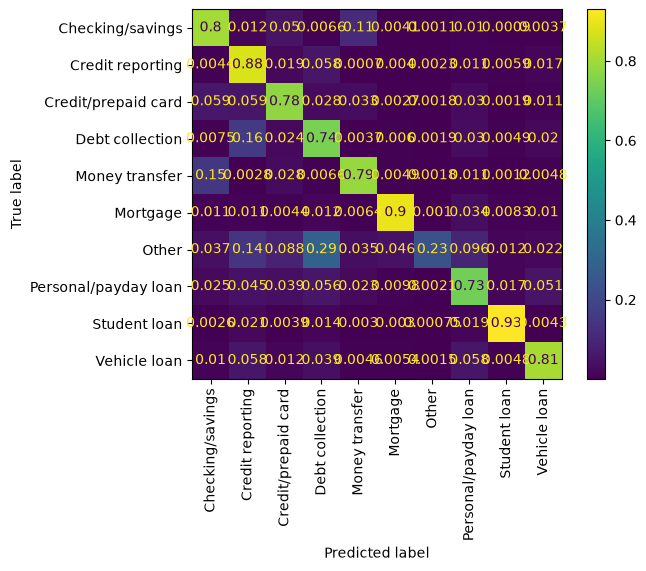

In [7]:
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

pred = clf.predict(Xva)
print("Macro-F1:", f1_score(y_val, pred, average="macro"))
print(classification_report(y_val, pred))
ConfusionMatrixDisplay.from_predictions(y_val, pred, xticks_rotation=90, normalize="true")